# 5. Analiza spektralna z wykorzystaniem rozwinięć falkowych

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-05.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 5.1. Norma falek przeskalowanych i ortonormalność falek Haara

In [2]:
import numpy as np

x = np.linspace(-40, 40, 400001)
dx = x[1] - x[0]

def haar(x):
    return (np.where((x >= 0) & (x < 0.5), 1.0, 0.0)
            - np.where((x >= 0.5) & (x < 1), 1.0, 0.0))

def kapelusz(x):                 # „meksykański kapelusz”
    c = 2/(np.sqrt(3)*np.pi**0.25)
    return c*(1 - x**2)*np.exp(-x**2/2)

def falka(psi, a, b):            # wzór (5.2)
    return psi((x - b)/a)/np.sqrt(a)

for a, b in ((1, 0), (0.5, 3), (4, -5)):
    print(a, b, round(np.sum(falka(kapelusz, a, b)**2)*dx, 4))

# macierz Grama dwunastu falek Haara z poziomów 0, 1, 2
rodzina = [falka(haar, 2.0**j, k*2.0**j)
           for j in (0, 1, 2) for k in (-2, -1, 0, 1)]
G = np.array([[np.sum(u*v)*dx for v in rodzina] for u in rodzina])
print(np.allclose(G, np.eye(12), atol=1e-3))

1 0 1.0
0.5 3 1.0
4 -5 1.0
True


### Kod 5.2. Ciągła transformata falkowa obliczona wprost ze wzoru (5.17)

In [3]:
import numpy as np

def kapelusz(x):
    c = 2/(np.sqrt(3)*np.pi**0.25)
    return c*(1 - x**2)*np.exp(-x**2/2)

def cwt(f, x, skale, psi=kapelusz):
    """Zwraca tablicę W[i, j] = W(skale[i], x[j])."""
    dx = x[1] - x[0]
    W = np.empty((len(skale), len(x)))
    for i, a in enumerate(skale):
        # macierz falek: wiersz j to falka przesunięta do x[j]
        P = psi((x[None, :] - x[:, None])/a)/np.sqrt(a)
        W[i] = P @ f*dx
    return W

x = np.linspace(-10, 10, 1001)
f = kapelusz((x - 2)/1.5)/np.sqrt(1.5)     # falka: a = 1,5, b = 2
skale = np.geomspace(0.25, 8, 41)
W = cwt(f, x, skale)

i, j = np.unravel_index(np.argmax(np.abs(W)), W.shape)
print("maksimum:", round(W[i, j], 3),
      "dla a =", round(skale[i], 2), "b =", round(x[j], 2))

maksimum: 0.999 dla a = 1.54 b = 2.0


### Kod 5.3. Stała dopuszczalności i odtworzenie sygnału ze wzoru (5.15)

In [4]:
import numpy as np

def kapelusz(x):
    c = 2/(np.sqrt(3)*np.pi**0.25)
    return c*(1 - x**2)*np.exp(-x**2/2)

# stała dopuszczalności (5.14); widmo falki jest znane
om = np.linspace(1e-6, 30, 300001)
widmo = (2/(np.sqrt(3)*np.pi**0.25)*np.sqrt(2*np.pi)
         * om**2*np.exp(-om**2/2))
C = np.sum(widmo**2/om)*(om[1] - om[0])
print("C_psi =", round(C, 4), " 4*sqrt(pi)/3 =",
      round(4*np.sqrt(np.pi)/3, 4))

x = np.linspace(-20, 20, 1001)
dx = x[1] - x[0]
f = np.exp(-(x + 3)**2)*np.sin(4*(x + 3)) + kapelusz(x - 4)

skale = np.geomspace(0.08, 40, 300)
da = np.gradient(skale)
odtw = np.zeros_like(x)
for a, d in zip(skale, da):
    P = kapelusz((x[None, :] - x[:, None])/a)/np.sqrt(a)
    W = P @ f*dx                    # W(a, b) dla wszystkich b
    odtw += (P.T @ W)*dx*d/a**2     # całka po b, krok po a
odtw /= C
print("błąd względny:",
      round(np.linalg.norm(odtw - f)/np.linalg.norm(f), 4))

C_psi = 2.3633  4*sqrt(pi)/3 = 2.3633
błąd względny: 0.0053


### Kod 5.4. Skalogram w bibliotece PyWavelets i przeliczenie skali na częstotliwość

In [5]:
import numpy as np
import pywt

fs = 200                                   # próbkowanie [Hz]
t = np.arange(0, 4, 1/fs)
s = np.where(t < 2, np.sin(2*np.pi*5*t), np.sin(2*np.pi*20*t))
s[500] += 4                                # impuls w t = 2,5 s

falka = "cmor1.5-1.0"                      # zespolona falka Morleta
czest = np.geomspace(2, 60, 60)            # żądane częstotliwości
skale = pywt.frequency2scale(falka, czest/fs)
W, f = pywt.cwt(s, skale, falka, sampling_period=1/fs)
print(W.shape, f[[0, -1]].round(1))

moc = np.abs(W)**2
for chwila in (1.0, 3.0):
    kol = int(chwila*fs)
    print(f"t = {chwila} s: maksimum mocy przy "
          f"{f[np.argmax(moc[:, kol])]:.1f} Hz")

(60, 800) [ 2. 60.]
t = 1.0 s: maksimum mocy przy 5.0 Hz
t = 3.0 s: maksimum mocy przy 20.1 Hz


### Kod 5.5. Transformata Haara ze wzorów (5.22) i z biblioteki PyWavelets

In [6]:
import numpy as np
import pywt

def haar_krok(c):
    """Jeden poziom transformaty Haara, wzór (5.22)."""
    return (c[0::2] + c[1::2])/np.sqrt(2), \
           (c[0::2] - c[1::2])/np.sqrt(2)

def haar_krok_odwrotny(c, d):
    """Odwrócenie jednego poziomu, wzór (5.23)."""
    wynik = np.empty(2*len(c))
    wynik[0::2] = (c + d)/np.sqrt(2)
    wynik[1::2] = (c - d)/np.sqrt(2)
    return wynik

f = np.array([4., 6, 10, 12, 8, 6, 5, 5])
c, detale = f, []
for poziom in (1, 2, 3):
    c, d = haar_krok(c)
    detale.append(d)
    print(poziom, c.round(3), d.round(3))

# to samo w PyWavelets
cA3, cD3, cD2, cD1 = pywt.wavedec(f, "haar", level=3)
print(np.allclose(c, cA3), np.allclose(detale[2], cD3),
      np.allclose(detale[1], cD2), np.allclose(detale[0], cD1))

# energia i odtworzenie sygnału
print(np.sum(f**2), np.sum(c**2) + sum(np.sum(d**2) for d in detale))
for d in reversed(detale):
    c = haar_krok_odwrotny(c, d)
print(np.allclose(c, f))

1 [ 7.071 15.556  9.899  7.071] [-1.414 -1.414  1.414  0.   ]
2 [16. 12.] [-6.  2.]
3 [19.799] [2.828]
True True True True
446.0 445.9999999999999
True


### Kod 5.6. Dekompozycja wielopoziomowa, liczba współczynników i odtworzenie sygnału

In [7]:
import numpy as np
import pywt

rng = np.random.default_rng(7)
t = np.linspace(0, 1, 1024, endpoint=False)
s = (np.sin(2*np.pi*4*t) + 0.5*np.sin(2*np.pi*90*t)*(t > 0.5)
     + 0.1*rng.normal(size=t.size))

print("największy sensowny poziom dla db4:",
      pywt.dwt_max_level(len(s), "db4"))

wsp = pywt.wavedec(s, "db4", level=4, mode="periodization")
nazwy = ["cA4", "cD4", "cD3", "cD2", "cD1"]
for nazwa, w in zip(nazwy, wsp):
    print(nazwa, len(w), f"energia: {np.sum(w**2):8.2f}")
print("razem:", sum(len(w) for w in wsp),
      "energia sygnału:", round(np.sum(s**2), 2))

odtworzony = pywt.waverec(wsp, "db4", mode="periodization")
print(np.allclose(odtworzony, s))

największy sensowny poziom dla db4: 7
cA4 64 energia:   511.76
cD4 64 energia:     1.77
cD3 128 energia:    56.73
cD2 256 energia:     8.25
cD1 512 energia:     4.44
razem: 1024 energia sygnału: 582.96
True


## Funkcje pomocnicze

Funkcje i dane, z których korzystają rozwiązania ćwiczeń.

In [8]:
from matplotlib.colors import LinearSegmentedColormap

def kapelusz(x):
    c = 2/(np.sqrt(3)*np.pi**0.25)
    return c*(1 - x**2)*np.exp(-x**2/2)

# mapa barw od przezroczystości do koloru: czytelna na jasnym i ciemnym tle
MAPA = LinearSegmentedColormap.from_list(
    "mapa", [(0.07, 0.45, 0.89, 0.0), (0.07, 0.45, 0.89, 1.0)])

## Ćwiczenia i rozwiązania

### Ćwiczenie 5.1
Sprawdź numerycznie, że falka „meksykański kapelusz” z kodu 5.1 ma zerową wartość średnią i jednostkową normę.

### Rozwiązanie 5.1

In [9]:
x = np.linspace(-20, 20, 400001)
dx = x[1] - x[0]
psi = 2/(np.sqrt(3)*np.pi**0.25)*(1 - x**2)*np.exp(-x**2/2)
print("całka:", round(np.sum(psi)*dx, 10))
print("norma:", round(np.sqrt(np.sum(psi**2)*dx), 10))

całka: -0.0
norma: 1.0


### Ćwiczenie 5.2
Oblicz ręcznie trzy poziomy transformaty Haara wektora (2, 4, 6, 8, 10, 12, 14, 16). Wynik sprawdź funkcją `pywt.wavedec`. Co można powiedzieć o współczynnikach detali sygnału liniowego?

### Rozwiązanie 5.2

In [10]:
f = np.arange(2., 17, 2)
for nazwa, w in zip(["cA3", "cD3", "cD2", "cD1"],
                    pywt.wavedec(f, "haar", level=3)):
    print(nazwa, w.round(3))
# Detale są stałe na każdym poziomie, lecz niezerowe: falka Haara ma jeden
# znikający moment. Falka db2 (dwa znikające momenty) zeruje detale
# sygnału liniowego poza brzegami:
print(pywt.dwt(np.arange(2., 66, 2), "db2")[1].round(6))

cA3 [25.456]
cD3 [-11.314]
cD2 [-4. -4.]
cD1 [-1.414 -1.414 -1.414 -1.414]
[-1.224745  0.        0.        0.        0.        0.        0.
  0.        0.        0.        0.       -0.       -0.        0.
 -0.       -0.        1.224745]


### Ćwiczenie 5.3
Wyzeruj w transformacie z przykładu 5.1 współczynniki detali poziomu pierwszego i odtwórz sygnał. Jak wygląda wynik?

### Rozwiązanie 5.3

In [11]:
f = np.array([4., 6, 10, 12, 8, 6, 5, 5])
cA3, cD3, cD2, cD1 = pywt.wavedec(f, "haar", level=3)
g = pywt.waverec([cA3, cD3, cD2, np.zeros_like(cD1)], "haar")
print(g)       # każda para próbek zastąpiona swoją średnią

[ 5.  5. 11. 11.  7.  7.  5.  5.]


### Ćwiczenie 5.4
Korzystając z kodu 5.2, wyznacz transformatę sygnału będącego skokiem jednostkowym w punkcie x = 0. Jak wartość maksymalna |W(a, b)| zależy od skali?

### Rozwiązanie 5.4

In [12]:
def kapelusz(x):
    c = 2/(np.sqrt(3)*np.pi**0.25)
    return c*(1 - x**2)*np.exp(-x**2/2)

x = np.linspace(-30, 30, 3001)
dx = x[1] - x[0]
f = (x >= 0).astype(float)
skale = np.array([0.25, 0.5, 1, 2, 4])
maks = []
for a in skale:
    P = kapelusz((x[None, :] - x[:, None])/a)/np.sqrt(a)
    W = P @ f*dx
    srodek = np.abs(x) < 15            # z dala od brzegów
    maks.append(np.max(np.abs(W[srodek])))
    print(f"a = {a}: max |W| = {maks[-1]:.4f}")
nachylenie = np.polyfit(np.log(skale), np.log(maks), 1)[0]
print("wykładnik:", round(nachylenie, 3), "(teoria: 0,5)")
# Dla skoku max |W| rośnie jak pierwiastek ze skali. Szybkość zaniku
# współczynników przy malejącej skali mierzy regularność sygnału.

a = 0.25: max |W| = 0.2632
a = 0.5: max |W| = 0.3719
a = 1.0: max |W| = 0.5260
a = 2.0: max |W| = 0.7439
a = 4.0: max |W| = 1.0521
wykładnik: 0.5 (teoria: 0,5)


### Ćwiczenie 5.5
Sygnał próbkowany z częstotliwością 1000 Hz rozłożono na pięć poziomów. Jakim pasmom częstotliwości odpowiadają współczynniki cD1, cD3 i cA5?

### Rozwiązanie 5.5

In [13]:
fs, J = 1000, 5
for j in range(1, J + 1):
    print(f"cD{j}: {fs/2**(j+1):7.2f} – {fs/2**j:7.2f} Hz")
print(f"cA{J}: {0:7.2f} – {fs/2**(J+1):7.2f} Hz")

cD1:  250.00 –  500.00 Hz
cD2:  125.00 –  250.00 Hz
cD3:   62.50 –  125.00 Hz
cD4:   31.25 –   62.50 Hz
cD5:   15.62 –   31.25 Hz
cA5:    0.00 –   15.62 Hz


### Ćwiczenie 5.6
Pokaż na przykładzie, że dyskretna transformata falkowa nie jest niezmiennicza względem przesunięcia: porównaj energie poziomów detali impulsu jednostkowego umieszczonego w próbce 64 i w próbce 65.

### Rozwiązanie 5.6

In [14]:
for falka in ("haar", "db2"):
    for p in (64, 65):
        s = np.zeros(256); s[p] = 1
        wsp = pywt.wavedec(s, falka, level=3, mode="periodization")
        energie = [round(float(np.sum(d**2)), 4) for d in wsp[:0:-1]]
        print(falka, "impuls w próbce", p, "energie cD1, cD2, cD3:", energie)
s = np.zeros(256); s[64] = 1
print(pywt.wavedec(s, "haar", level=3)[1:][-1][30:34].round(3))
s = np.zeros(256); s[65] = 1
print(pywt.wavedec(s, "haar", level=3)[1:][-1][30:34].round(3))

haar impuls w próbce 64 energie cD1, cD2, cD3: [0.5, 0.25, 0.125]
haar impuls w próbce 65 energie cD1, cD2, cD3: [0.5, 0.25, 0.125]
db2 impuls w próbce 64 energie cD1, cD2, cD3: [0.2835, 0.2916, 0.1942]
db2 impuls w próbce 65 energie cD1, cD2, cD3: [0.7165, 0.1408, 0.0464]
[0.    0.    0.707 0.   ]
[ 0.     0.    -0.707  0.   ]


### Ćwiczenie 5.7
Zmień w kodzie 5.4 falkę Morleta na „meksykański kapelusz” (`"mexh"`). Jak zmienia się obraz składowych sinusoidalnych, a jak obraz impulsu?

### Rozwiązanie 5.7

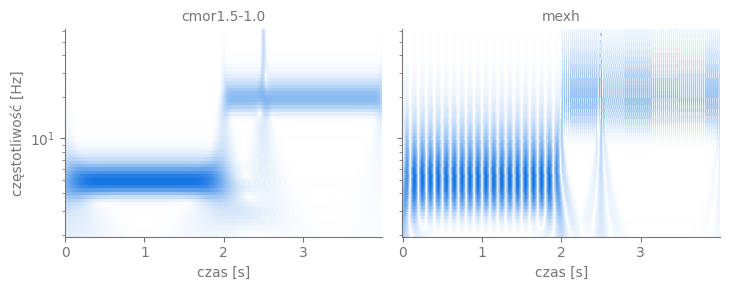

In [15]:
from matplotlib.colors import LinearSegmentedColormap
MAPA = LinearSegmentedColormap.from_list(
    "mapa", [(0.07, 0.45, 0.89, 0.0), (0.07, 0.45, 0.89, 1.0)])
fs = 200
t = np.arange(0, 4, 1/fs)
s = np.where(t < 2, np.sin(2*np.pi*5*t), np.sin(2*np.pi*20*t))
s[500] += 4
czest = np.geomspace(2, 60, 60)
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), sharey=True)
for ax, falka in zip(axs, ("cmor1.5-1.0", "mexh")):
    skale = pywt.frequency2scale(falka, czest/fs)
    W, fr = pywt.cwt(s, skale, falka, sampling_period=1/fs)
    ax.pcolormesh(t, fr, np.abs(W), cmap=MAPA, shading="auto")
    ax.set_yscale("log"); ax.set_title(falka); ax.set_xlabel("czas [s]")
axs[0].set_ylabel("częstotliwość [Hz]")
plt.tight_layout(); plt.show()
# Falka rzeczywista daje obraz prążkowany (współczynniki oscylują razem
# z sygnałem) i szersze pasma w częstotliwości, za to ostrzej lokalizuje impuls.

### Ćwiczenie 5.8
Wyznacz skalogram sygnału o częstotliwości rosnącej liniowo od 5 Hz do 50 Hz. Porównaj go ze spektrogramem z ćwiczenia 3.8.

### Rozwiązanie 5.8

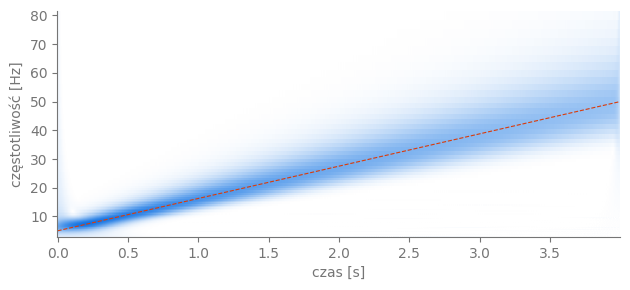

In [16]:
from scipy.signal import chirp
fs = 400
t = np.arange(0, 4, 1/fs)
s = chirp(t, f0=5, t1=4, f1=50)
falka = "cmor1.5-1.0"
czest = np.geomspace(3, 80, 80)
skale = pywt.frequency2scale(falka, czest/fs)
W, fr = pywt.cwt(s, skale, falka, sampling_period=1/fs)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.pcolormesh(t, fr, np.abs(W), cmap=MAPA, shading="auto")
ax.plot(t, 5 + 45*t/4, color=RDZAWY, lw=0.8, ls="--")
ax.set_xlabel("czas [s]"); ax.set_ylabel("częstotliwość [Hz]")
plt.tight_layout(); plt.show()
# Na osi liniowej grzbiet skalogramu biegnie wzdłuż prostej 5 + 11,25 t.
# Pasmo jest wąskie przy niskich częstotliwościach i poszerza się ku wysokim:
# rozdzielczość względna (Δf/f) jest stała.